# Homework 7.1 - Part III

## From Trajectories to Images

Part II constructed the numerical trajectory

$$
\Gamma_c
\in
\mathbb{R}^{3(M+1)}.
$$

Part III defines a rendering map

$$
\boxed{
R:
\Gamma_c
\longmapsto
I_c
}
$$

that converts the trajectory into a fixed-size RGB image.

The purpose of this part is not only to create an image, but also to understand what mathematical information is preserved and what is lost during rendering.

# 1. Dimensions of the Input and Output

For the reference experiment,

$$
T=25,
\qquad
\Delta t=0.01,
$$

so

$$
M=2500
$$

and

$$
M+1=2501.
$$

Therefore the discretized trajectory has dimension

$$
\Gamma_c
\in
\mathbb{R}^{3(2501)}
=
\mathbb{R}^{7503}.
$$

The rendering will use

$$
H=W=256
$$

with three RGB channels.

Hence

$$
I_c
\in
\mathbb{R}^{3(256)(256)}
=
\mathbb{R}^{196608}.
$$

Pixel values are stored as unsigned 8-bit integers in the PNG file. After division by 255, the same image may be regarded as a point in

$$
[0,1]^{196608}
\subset
\mathbb{R}^{196608}.
$$

# 2. Chosen Rendering Map

For a trajectory

$$
\Gamma_c
=
\{(x(t_j),y(t_j),z(t_j))\}_{j=0}^{M},
$$

we define the rendered scientific image to be the

$$
(x,z)
$$

phase-space projection.

Thus the geometric projection is

$$
P:
(x,y,z)
\longmapsto
(x,z).
$$

The rendering map then performs four operations:

1. project every state from $$\mathbb{R}^3$$ to $$\mathbb{R}^2$$;
2. linearly normalize the physical plotting region to a 256-by-256 pixel grid;
3. connect consecutive projected trajectory samples by line segments;
4. store the raster as an RGB image.

This produces a deterministic map once the plotting bounds, image dimensions, line width, and background are fixed.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw7_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw7_1"

trajectory_path = (
    DATA_DIR
    / "part2_reference_trajectory.csv"
)

if not trajectory_path.exists():
    raise FileNotFoundError(
        "Run Part II first so the reference trajectory exists."
    )

trajectory = pd.read_csv(
    trajectory_path
)

x = trajectory["x"].to_numpy()
z = trajectory["z"].to_numpy()

H = 256
W = 256
LINE_WIDTH = 1
BACKGROUND = (255, 255, 255)
FOREGROUND = (0, 0, 0)

print("Trajectory rows:", len(trajectory))
print("Image size:", (W, H))

Trajectory rows: 2501
Image size: (256, 256)


# 3. Freeze reference rendering bounds

For this Part III demonstration, the physical bounds are fitted from the reference trajectory itself with a 5% margin.

Part IV will use a stricter dataset rule: rendering bounds will be fitted from the **training trajectories only** and then frozen before rendering validation and test samples.

In [2]:
x_min_raw = float(x.min())
x_max_raw = float(x.max())
z_min_raw = float(z.min())
z_max_raw = float(z.max())

x_span = x_max_raw - x_min_raw
z_span = z_max_raw - z_min_raw

x_min = (
    x_min_raw
    - 0.05 * x_span
)

x_max = (
    x_max_raw
    + 0.05 * x_span
)

z_min = (
    z_min_raw
    - 0.05 * z_span
)

z_max = (
    z_max_raw
    + 0.05 * z_span
)

render_config = {
    "projection": "x-z",
    "width": W,
    "height": H,
    "line_width": LINE_WIDTH,
    "background_rgb": list(
        BACKGROUND
    ),
    "foreground_rgb": list(
        FOREGROUND
    ),
    "x_bounds": [
        x_min,
        x_max,
    ],
    "z_bounds": [
        z_min,
        z_max,
    ],
    "bound_fit_rule": (
        "reference trajectory min/max "
        "with 5% padding"
    ),
}

config_path = (
    DATA_DIR
    / "part3_reference_rendering_config.json"
)

config_path.write_text(
    json.dumps(
        render_config,
        indent=2,
    ),
    encoding="utf-8",
)

print(json.dumps(render_config, indent=2))
print("Saved:", config_path.resolve())

{
  "projection": "x-z",
  "width": 256,
  "height": 256,
  "line_width": 1,
  "background_rgb": [
    255,
    255,
    255
  ],
  "foreground_rgb": [
    0,
    0,
    0
  ],
  "x_bounds": [
    -19.060481488321912,
    21.39393132629259
  ],
  "z_bounds": [
    -1.381877183126769,
    50.17764287627354
  ],
  "bound_fit_rule": "reference trajectory min/max with 5% padding"
}
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\data\hw7_1\part3_reference_rendering_config.json


# 4. Exact rasterization

The coordinate transform is

$$
u
=
\frac{x-x_{\min}}
{x_{\max}-x_{\min}}
(W-1),
$$

and

$$
v
=
(H-1)
-
\frac{z-z_{\min}}
{z_{\max}-z_{\min}}
(H-1).
$$

The vertical coordinate is reversed because pixel row zero is at the top of an image.

Consecutive transformed points are joined by straight raster line segments.

In [3]:
def physical_to_pixel(
    x_value,
    z_value,
    x_bounds,
    z_bounds,
    width,
    height,
):
    x_min, x_max = x_bounds
    z_min, z_max = z_bounds

    u = (
        (x_value - x_min)
        / (x_max - x_min)
        * (width - 1)
    )

    v = (
        (height - 1)
        - (
            (z_value - z_min)
            / (z_max - z_min)
            * (height - 1)
        )
    )

    return (
        float(u),
        float(v),
    )


def render_xz_trajectory(
    x_values,
    z_values,
    x_bounds,
    z_bounds,
    width=256,
    height=256,
    line_width=1,
):
    image = Image.new(
        "RGB",
        (width, height),
        BACKGROUND,
    )

    draw = ImageDraw.Draw(
        image
    )

    points = [
        physical_to_pixel(
            x_value,
            z_value,
            x_bounds,
            z_bounds,
            width,
            height,
        )
        for x_value, z_value
        in zip(
            x_values,
            z_values,
        )
    ]

    draw.line(
        points,
        fill=FOREGROUND,
        width=line_width,
        joint="curve",
    )

    return image


image = render_xz_trajectory(
    x,
    z,
    x_bounds=(
        x_min,
        x_max,
    ),
    z_bounds=(
        z_min,
        z_max,
    ),
    width=W,
    height=H,
    line_width=LINE_WIDTH,
)

image_path = (
    RESULT_DIR
    / "part3_reference_rendered_image.png"
)

image.save(
    image_path
)

print("Saved:", image_path.resolve())
print("Image mode:", image.mode)
print("Image size:", image.size)

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\result images\hw7_1\part3_reference_rendered_image.png
Image mode: RGB
Image size: (256, 256)


# 5. Verify the output image dimensions

In [4]:
loaded_image = Image.open(
    image_path
).convert("RGB")

image_array = np.asarray(
    loaded_image
)

expected_shape = (
    H,
    W,
    3,
)

if image_array.shape != expected_shape:
    raise ValueError(
        f"Expected image shape {expected_shape}, "
        f"found {image_array.shape}."
    )

flattened = (
    image_array
    .astype(np.float32)
    .reshape(-1)
    / 255.0
)

dimension_record = {
    "trajectory_samples": len(
        trajectory
    ),
    "trajectory_vector_dimension": int(
        3 * len(trajectory)
    ),
    "image_height": H,
    "image_width": W,
    "image_channels": 3,
    "image_array_shape": list(
        image_array.shape
    ),
    "flattened_image_dimension": int(
        flattened.size
    ),
    "normalized_pixel_min": float(
        flattened.min()
    ),
    "normalized_pixel_max": float(
        flattened.max()
    ),
}

dimension_path = (
    DATA_DIR
    / "part3_dimension_verification.json"
)

dimension_path.write_text(
    json.dumps(
        dimension_record,
        indent=2,
    ),
    encoding="utf-8",
)

print(json.dumps(dimension_record, indent=2))
print("Saved:", dimension_path.resolve())

{
  "trajectory_samples": 2501,
  "trajectory_vector_dimension": 7503,
  "image_height": 256,
  "image_width": 256,
  "image_channels": 3,
  "image_array_shape": [
    256,
    256,
    3
  ],
  "flattened_image_dimension": 196608,
  "normalized_pixel_min": 0.0,
  "normalized_pixel_max": 1.0
}
Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\data\hw7_1\part3_dimension_verification.json


# 6. Display the rendered image

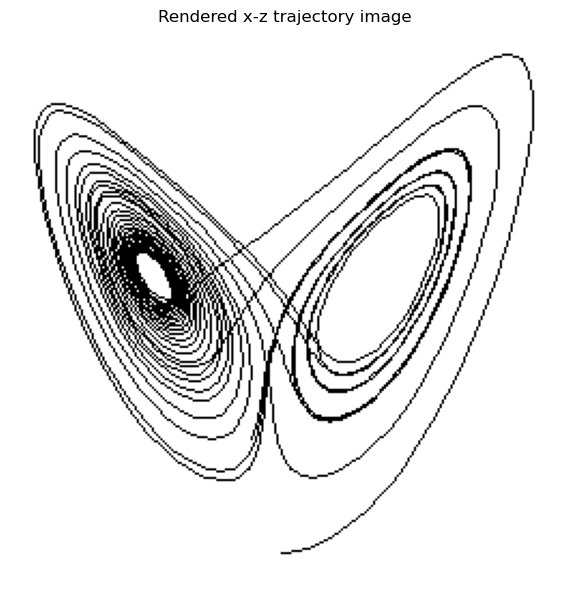

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.1\result images\hw7_1\part3_reference_rendered_image_display.png


In [5]:
plt.figure(figsize=(6, 6))
plt.imshow(
    loaded_image
)
plt.axis("off")
plt.title(
    "Rendered x-z trajectory image"
)
plt.tight_layout()

display_path = (
    RESULT_DIR
    / "part3_reference_rendered_image_display.png"
)

plt.savefig(
    display_path,
    dpi=200,
)

plt.show()

print("Saved:", display_path.resolve())

# 7. Is the rendering map one-to-one?

No.

The chosen rendering map

$$
R:
\Gamma_c
\longmapsto
I_c
$$

is not injective.

There are several independent reasons.

## Loss of the y-coordinate

The rendering first applies

$$
(x,y,z)
\longmapsto
(x,z).
$$

Therefore two three-dimensional trajectories with the same sampled $$x$$ and $$z$$ coordinates but different $$y$$ coordinates produce the same projected curve.

Thus the full state cannot be reconstructed from the image.

## Loss of exact numerical precision

The continuous plotting region is quantized to only

$$
256\times256
$$

pixel locations.

Different physical coordinates can round to the same pixel.

Consequently, many nearby numerical trajectories can produce identical rasterized lines.

## Loss of exact time information

A phase portrait shows the geometric path but does not directly encode the exact sample time

$$
t_j
$$

associated with each point.

The rendered black line also does not indicate trajectory speed.

Two paths with the same geometric curve but different time parametrizations can therefore render identically.

## Line thickness and rasterization

A one-pixel line represents a region rather than an exact mathematical point.

Nearby curves can occupy the same raster pixels.

## Finite image resolution

The input trajectory contains

$$
7503
$$

floating-point state coordinates, while the output is a finite raster with quantized RGB values.

Although the raw image vector has many coordinates, those coordinates describe a visual encoding, not an invertible storage of the original numerical states.

# 8. What can still be recovered from the image?

The rendering preserves useful qualitative structure.

For example, the image can reveal:

- the existence of two Lorenz lobes;
- approximate horizontal and vertical extent;
- whether the trajectory occupies the familiar attractor region;
- coarse differences between trajectories generated under different conditions.

But it does not preserve enough information to recover:

- exact state values;
- the omitted $$y$$ coordinate;
- precise sample times;
- trajectory speed;
- the ODE residual;
- the parameter vector $$c$$ uniquely.

Therefore

$$
I_c
$$

should be interpreted as a **visual representation** of the mathematical trajectory rather than a replacement for the trajectory itself.

# Part III Conclusion

The second map has now been implemented:

$$
\boxed{
\Gamma_c
\longmapsto
I_c.
}
$$

The image has exact shape

$$
256\times256\times3,
$$

or flattened dimension

$$
196{,}608.
$$

The rendering map is many-to-one.

Part IV will use this same scientific idea to build a small dataset of condition vectors, numerical Lorenz trajectories, and rendered trajectory images.